In [529]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import warnings
warnings.filterwarnings("ignore")

In [530]:
df = pd.read_csv(
    r"C:\Users\hp\OneDrive\Desktop\Aircraft_ML_Project\aircraft_sensor_dataset_file.csv"
)

In [531]:
df.head(5)

,unnamed 1,Flight_Hours,Oil_Pressure,Aircraft_ID,Enginerpm (N1),Operating_Modes,unnamed 3,Engine_Vibration,Fuel_Pressure,Air_Pressure (P2/P3),Fuel_Flow,Engine_Temperature (EGT),Enginerpm (N2),Engine_Types,unnamed 2,Health_Label
0,NaN,16761.7 Hr,66.2 PSI,AC-0190,83.8 %,Cruise,0.0,5.06 Units,48.1 PSI,225.1 PSI,4117 PPH,1009 °C,93.0 %,PW1000G,0.0,Normal
1,NaN,4186.1 Hr,71.8 PSI,AC-0250,83.3 %,Climb,0.0,4.29 Units,48.3 PSI,266.6 PSI,7626 PPH,917 °C,96.8 %,Trent1000,0.0,Normal
2,NaN,3275.3 Hr,57.8 PSI,AC-0506,79.5 %,Cruise,0.0,6.44 Units,43.0 PSI,221.5 PSI,7535 PPH,1058 °C,96.3 %,Trent700,0.0,Caution
3,NaN,26424.4 Hr,69.8 PSI,AC-0533,64.8 %,Landing,0.0,2.48 Units,47.3 PSI,233.7 PSI,6414 PPH,789 °C,90.5 %,Trent1000,0.0,Normal
4,NaN,12550.5 Hr,27.7 PSI,AC-0130,16.4 %,Ground,0.0,4.72 Units,23.5 PSI,152.7 PSI,882 PPH,716 °C,64.1 %,CFM56,0.0,Abnormal


In [532]:
df.tail(5)

,unnamed 1,Flight_Hours,Oil_Pressure,Aircraft_ID,Enginerpm (N1),Operating_Modes,unnamed 3,Engine_Vibration,Fuel_Pressure,Air_Pressure (P2/P3),Fuel_Flow,Engine_Temperature (EGT),Enginerpm (N2),Engine_Types,unnamed 2,Health_Label
11281,NaN,21293.3 Hr,50.8 PSI,AC-0218,78.4 %,Cruise,0.0,4.09 Units,54.4 PSI,211.8 PSI,8684 PPH,1000 °C,85.7 %,Trent1000,0.0,Caution
11282,NaN,4887.7 Hr,54.2 PSI,AC-0157,49.2 %,Descent,0.0,3.59 Units,41.3 PSI,190.3 PSI,5222 PPH,692 °C,77.2 %,Trent1000,0.0,Normal
11283,NaN,1203.4 Hr,59.7 PSI,AC-0481,89.4 %,Climb,0.0,6.23 Units,47.3 PSI,235.8 PSI,10212 PPH,1100 °C,95.5 %,GEnx,0.0,Caution
11284,NaN,25856.2 Hr,57.7 PSI,AC-0503,66.6 %,Landing,0.0,6.28 Units,46.6 PSI,178.8 PSI,4652 PPH,975 °C,88.4 %,CFM56,0.0,Caution
11285,NaN,24557.6 Hr,34.6 PSI,AC-0540,61.6 %,Landing,0.0,6.46 Units,38.4 PSI,120.1 PSI,3565 PPH,1001 °C,77.8 %,CFM56,0.0,Abnormal


In [533]:
df.sample(5)

,unnamed 1,Flight_Hours,Oil_Pressure,Aircraft_ID,Enginerpm (N1),Operating_Modes,unnamed 3,Engine_Vibration,Fuel_Pressure,Air_Pressure (P2/P3),Fuel_Flow,Engine_Temperature (EGT),Enginerpm (N2),Engine_Types,unnamed 2,Health_Label
10307,NaN,9650.7 Hr,57.6 PSI,AC-0452,63.7 %,Landing,0.0,5.95 Units,31.0 PSI,187.9 PSI,3220 PPH,938 °C,84.9 %,PW1000G,0.0,Caution
10082,NaN,8148.0 Hr,61.5 PSI,AC-0456,88.8 %,Climb,0.0,5.47 Units,53.4 PSI,241.6 PSI,5286 PPH,979 °C,100.0 %,CFM LEAP,0.0,Normal
166,NaN,33055.5 Hr,26.3 PSI,AC-0547,22.2 %,Ground,0.0,4.61 Units,26.1 PSI,124.4 PSI,1458 PPH,670 °C,58.5 %,Trent700,0.0,Caution
10409,NaN,8339.7 Hr,66.6 PSI,AC-0488,88.3 %,Climb,0.0,4.76 Units,51.2 PSI,209.4 PSI,7041 PPH,965 °C,100.4 %,Trent700,0.0,Normal
1536,NaN,6199.8 Hr,47.0 PSI,AC-0477,55.0 %,Descent,0.0,4.78 Units,34.7 PSI,190.6 PSI,5417 PPH,904 °C,81.0 %,Trent1000,0.0,Abnormal


In [534]:
df.columns


Index(['unnamed 1', 'Flight_Hours', 'Oil_Pressure', 'Aircraft_ID',
       'Enginerpm (N1)', 'Operating_Modes', 'unnamed 3', 'Engine_Vibration',
       'Fuel_Pressure', 'Air_Pressure (P2/P3)', 'Fuel_Flow',
       'Engine_Temperature (EGT)', 'Enginerpm (N2)', 'Engine_Types',
       'unnamed 2', 'Health_Label'],
      dtype='str')

In [535]:
df.index


RangeIndex(start=0, stop=11286, step=1)

In [536]:
df.shape


(11286, 16)

In [537]:
df.size


180576

In [538]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 11286 entries, 0 to 11285
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   unnamed 1                 0 non-null      float64
 1   Flight_Hours              11286 non-null  str    
 2   Oil_Pressure              11286 non-null  str    
 3   Aircraft_ID               11286 non-null  str    
 4   Enginerpm (N1)            11286 non-null  str    
 5   Operating_Modes           11278 non-null  str    
 6   unnamed 3                 11286 non-null  float64
 7   Engine_Vibration          11286 non-null  str    
 8   Fuel_Pressure             11286 non-null  str    
 9   Air_Pressure (P2/P3)      11286 non-null  str    
 10  Fuel_Flow                 11286 non-null  str    
 11  Engine_Temperature (EGT)  11286 non-null  str    
 12  Enginerpm (N2)            11286 non-null  str    
 13  Engine_Types              11274 non-null  str    
 14  unnamed 2        

In [539]:
df.dtypes


unnamed 1                   float64
Flight_Hours                    str
Oil_Pressure                    str
Aircraft_ID                     str
Enginerpm (N1)                  str
Operating_Modes                 str
unnamed 3                   float64
Engine_Vibration                str
Fuel_Pressure                   str
Air_Pressure (P2/P3)            str
Fuel_Flow                       str
Engine_Temperature (EGT)        str
Enginerpm (N2)                  str
Engine_Types                    str
unnamed 2                   float64
Health_Label                    str
dtype: object

In [540]:
df.isnull().sum()


unnamed 1                   11286
Flight_Hours                    0
Oil_Pressure                    0
Aircraft_ID                     0
Enginerpm (N1)                  0
Operating_Modes                 8
unnamed 3                       0
Engine_Vibration                0
Fuel_Pressure                   0
Air_Pressure (P2/P3)            0
Fuel_Flow                       0
Engine_Temperature (EGT)        0
Enginerpm (N2)                  0
Engine_Types                   12
unnamed 2                       0
Health_Label                    0
dtype: int64

In [541]:
df.notnull().sum()


unnamed 1                       0
Flight_Hours                11286
Oil_Pressure                11286
Aircraft_ID                 11286
Enginerpm (N1)              11286
Operating_Modes             11278
unnamed 3                   11286
Engine_Vibration            11286
Fuel_Pressure               11286
Air_Pressure (P2/P3)        11286
Fuel_Flow                   11286
Engine_Temperature (EGT)    11286
Enginerpm (N2)              11286
Engine_Types                11274
unnamed 2                   11286
Health_Label                11286
dtype: int64

In [542]:
df.count()


unnamed 1                       0
Flight_Hours                11286
Oil_Pressure                11286
Aircraft_ID                 11286
Enginerpm (N1)              11286
Operating_Modes             11278
unnamed 3                   11286
Engine_Vibration            11286
Fuel_Pressure               11286
Air_Pressure (P2/P3)        11286
Fuel_Flow                   11286
Engine_Temperature (EGT)    11286
Enginerpm (N2)              11286
Engine_Types                11274
unnamed 2                   11286
Health_Label                11286
dtype: int64

In [543]:
df.nunique()


unnamed 1                       0
Flight_Hours                11044
Oil_Pressure                  642
Aircraft_ID                   640
Enginerpm (N1)                783
Operating_Modes                 6
unnamed 3                       1
Engine_Vibration              833
Fuel_Pressure                 461
Air_Pressure (P2/P3)         1858
Fuel_Flow                    6643
Engine_Temperature (EGT)      636
Enginerpm (N2)                518
Engine_Types                    7
unnamed 2                       1
Health_Label                    3
dtype: int64

In [544]:
df.duplicated().sum()


np.int64(3)

In [545]:
df.drop(columns=["unnamed 1", "unnamed 2", "unnamed 3"], inplace=True)
df.drop(columns=["Aircraft_ID"], inplace=True)
df.drop_duplicates(inplace=True)

df.shape

(11283, 12)

In [546]:
df["Operating_Modes"] = df["Operating_Modes"].fillna("Unknown Mode")

df["Engine_Types"] = df["Engine_Types"].fillna("Unknown Type")

df.isnull().sum()


Flight_Hours                0
Oil_Pressure                0
Enginerpm (N1)              0
Operating_Modes             0
Engine_Vibration            0
Fuel_Pressure               0
Air_Pressure (P2/P3)        0
Fuel_Flow                   0
Engine_Temperature (EGT)    0
Enginerpm (N2)              0
Engine_Types                0
Health_Label                0
dtype: int64

In [547]:
df.rename(columns={"Enginerpm (N1)": "Engine_RPM (N1)", "Enginerpm (N2)": "Engine_RPM (N2)" }, inplace=True)

df.columns

Index(['Flight_Hours', 'Oil_Pressure', 'Engine_RPM (N1)', 'Operating_Modes',
       'Engine_Vibration', 'Fuel_Pressure', 'Air_Pressure (P2/P3)',
       'Fuel_Flow', 'Engine_Temperature (EGT)', 'Engine_RPM (N2)',
       'Engine_Types', 'Health_Label'],
      dtype='str')

In [548]:
df["Oil_Pressure"] = df["Oil_Pressure"].str.replace(" PSI", "", regex=False).astype(float)

df["Engine_RPM (N1)"] = df["Engine_RPM (N1)"].str.replace(" %", "", regex=False).astype(float)

df["Engine_RPM (N2)"] = df["Engine_RPM (N2)"].str.replace(" %", "", regex=False).astype(float)

df["Engine_Vibration"] = df["Engine_Vibration"].str.replace(" Units", "", regex=False).astype(float)

df["Flight_Hours"] = df["Flight_Hours"].str.replace(" Hr", "", regex=False).astype(float)

df["Fuel_Pressure"] = df["Fuel_Pressure"].str.replace(" PSI", "", regex=False).astype(float)

df["Air_Pressure (P2/P3)"] = df["Air_Pressure (P2/P3)"].str.replace(" PSI", "", regex=False).astype(float)

df["Fuel_Flow"] = df["Fuel_Flow"].str.replace(" PPH", "", regex=False).astype(float)

df["Engine_Temperature (EGT)"] = df["Engine_Temperature (EGT)"].str.replace(" °C", "", regex=False).astype(float)

print(df.dtypes)

Flight_Hours                float64
Oil_Pressure                float64
Engine_RPM (N1)             float64
Operating_Modes                 str
Engine_Vibration            float64
Fuel_Pressure               float64
Air_Pressure (P2/P3)        float64
Fuel_Flow                   float64
Engine_Temperature (EGT)    float64
Engine_RPM (N2)             float64
Engine_Types                    str
Health_Label                    str
dtype: object


In [549]:
df.info()

<class 'pandas.DataFrame'>
Index: 11283 entries, 0 to 11285
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Flight_Hours              11283 non-null  float64
 1   Oil_Pressure              11283 non-null  float64
 2   Engine_RPM (N1)           11283 non-null  float64
 3   Operating_Modes           11283 non-null  str    
 4   Engine_Vibration          11283 non-null  float64
 5   Fuel_Pressure             11283 non-null  float64
 6   Air_Pressure (P2/P3)      11283 non-null  float64
 7   Fuel_Flow                 11283 non-null  float64
 8   Engine_Temperature (EGT)  11283 non-null  float64
 9   Engine_RPM (N2)           11283 non-null  float64
 10  Engine_Types              11283 non-null  str    
 11  Health_Label              11283 non-null  str    
dtypes: float64(9), str(3)
memory usage: 1.1 MB


In [550]:
df.describe()

,Flight_Hours,Oil_Pressure,Engine_RPM (N1),Engine_Vibration,Fuel_Pressure,Air_Pressure (P2/P3),Fuel_Flow,Engine_Temperature (EGT),Engine_RPM (N2)
count,11283.000000,11283.000000,11283.000000,11283.000000,11283.000000,11283.000000,11283.000000,11283.000000,11283.000000
mean,19641.219516,55.446521,67.589028,5.308623,42.588992,202.946291,6033.816715,900.516972,85.368067
std,12783.683792,11.385287,23.631433,1.540736,10.273234,39.078000,2900.450140,157.104771,11.147697
min,634.200000,20.000000,15.000000,0.270000,20.000000,62.700000,150.000000,434.000000,55.000000
25%,10411.450000,47.800000,55.400000,4.250000,36.000000,177.500000,3805.000000,802.000000,78.900000
50%,17051.200000,55.800000,76.200000,5.320000,44.100000,205.300000,5652.000000,929.000000,87.600000
75%,25915.750000,63.400000,86.100000,6.360000,50.200000,230.600000,8237.000000,1027.000000,93.900000
max,60000.000000,92.500000,105.000000,10.000000,69.400000,323.800000,12000.000000,1100.000000,110.000000


In [551]:
print("Operating Modes:")
print(df["Operating_Modes"].unique())
print(df["Operating_Modes"].value_counts())


Operating Modes:
<StringArray>
['Cruise', 'Climb', 'Landing', 'Ground', 'Takeoff', 'Descent', 'Unknown Mode']
Length: 7, dtype: str
Operating_Modes
Cruise          2858
Climb           1941
Ground          1869
Landing         1675
Descent         1612
Takeoff         1320
Unknown Mode       8
Name: count, dtype: int64


In [552]:

print("\nEngine Types:")
print(df["Engine_Types"].unique())
print(df["Engine_Types"].value_counts())



Engine Types:
<StringArray>
[     'PW1000G',    'Trent1000',     'Trent700',        'CFM56',
     'CFM LEAP',         'GE90',         'GEnx', 'Unknown Type']
Length: 8, dtype: str
Engine_Types
GEnx            1693
Trent1000       1682
GE90            1643
Trent700        1632
PW1000G         1566
CFM LEAP        1553
CFM56           1502
Unknown Type      12
Name: count, dtype: int64


In [553]:

print("\nHealth Label:")
print(df["Health_Label"].unique())
print(df["Health_Label"].value_counts())


Health Label:
<StringArray>
['Normal', 'Caution', 'Abnormal']
Length: 3, dtype: str
Health_Label
Normal      5459
Caution     3779
Abnormal    2045
Name: count, dtype: int64


In [554]:
df[df["Health_Label"] == "Normal"].sample(5)

,Flight_Hours,Oil_Pressure,Engine_RPM (N1),Operating_Modes,Engine_Vibration,Fuel_Pressure,Air_Pressure (P2/P3),Fuel_Flow,Engine_Temperature (EGT),Engine_RPM (N2),Engine_Types,Health_Label
4262,13239.6,83.3,93.6,Takeoff,5.32,54.9,270.5,12000.0,1059.0,98.6,GE90,Normal
3306,19811.5,68.7,91.9,Takeoff,5.37,47.9,267.5,9032.0,1010.0,97.9,Trent1000,Normal
9369,6823.7,44.0,20.2,Ground,3.15,28.7,136.5,1181.0,527.0,67.1,Trent700,Normal
8207,4090.3,70.9,74.5,Cruise,5.01,40.5,201.3,6408.0,904.0,90.1,Trent700,Normal
5162,18864.2,66.0,21.0,Ground,1.68,27.3,182.4,1460.0,525.0,69.5,CFM LEAP,Normal


In [555]:
df[df["Health_Label"] == "Abnormal"][
    ["Oil_Pressure", "Health_Label"]
].sample(5)

,Oil_Pressure,Health_Label
10144,47.7,Abnormal
8730,50.1,Abnormal
2736,45.6,Abnormal
4484,58.2,Abnormal
3496,50.0,Abnormal


In [556]:
df[df["Health_Label"] == "Caution"][
    ["Engine_Vibration", "Engine_Temperature (EGT)", "Health_Label"]
].sample(5)

,Engine_Vibration,Engine_Temperature (EGT),Health_Label
8942,5.45,849.0,Caution
11071,6.62,1062.0,Caution
922,5.48,950.0,Caution
6944,4.08,782.0,Caution
3953,5.59,1046.0,Caution


In [557]:
df[(df["Health_Label"] == "Abnormal") & (df["Engine_Vibration"] > 7)][
    ["Engine_Vibration", "Oil_Pressure", "Health_Label"]
].sample(5)

,Engine_Vibration,Oil_Pressure,Health_Label
3858,8.54,48.1,Abnormal
3225,7.20,27.3,Abnormal
1355,7.43,53.6,Abnormal
359,9.04,42.9,Abnormal
5507,7.46,49.8,Abnormal


In [558]:
df[
    (df["Health_Label"] == "Abnormal") |
    (df["Health_Label"] == "Caution")
][["Engine_Temperature (EGT)", "Engine_Vibration", "Health_Label"]].sample(5)

,Engine_Temperature (EGT),Engine_Vibration,Health_Label
2751,1086.0,6.05,Caution
2257,972.0,7.94,Abnormal
5406,1100.0,6.91,Abnormal
85,629.0,4.79,Caution
3126,790.0,5.01,Abnormal


In [559]:
df[
    ~(df["Health_Label"] == "Normal")
][
    ["Oil_Pressure", "Engine_Vibration", "Health_Label"]
].sample(5)

,Oil_Pressure,Engine_Vibration,Health_Label
6289,41.7,7.07,Abnormal
2892,37.9,6.92,Abnormal
824,58.2,4.26,Caution
8124,51.2,6.74,Abnormal
3556,70.7,6.62,Caution


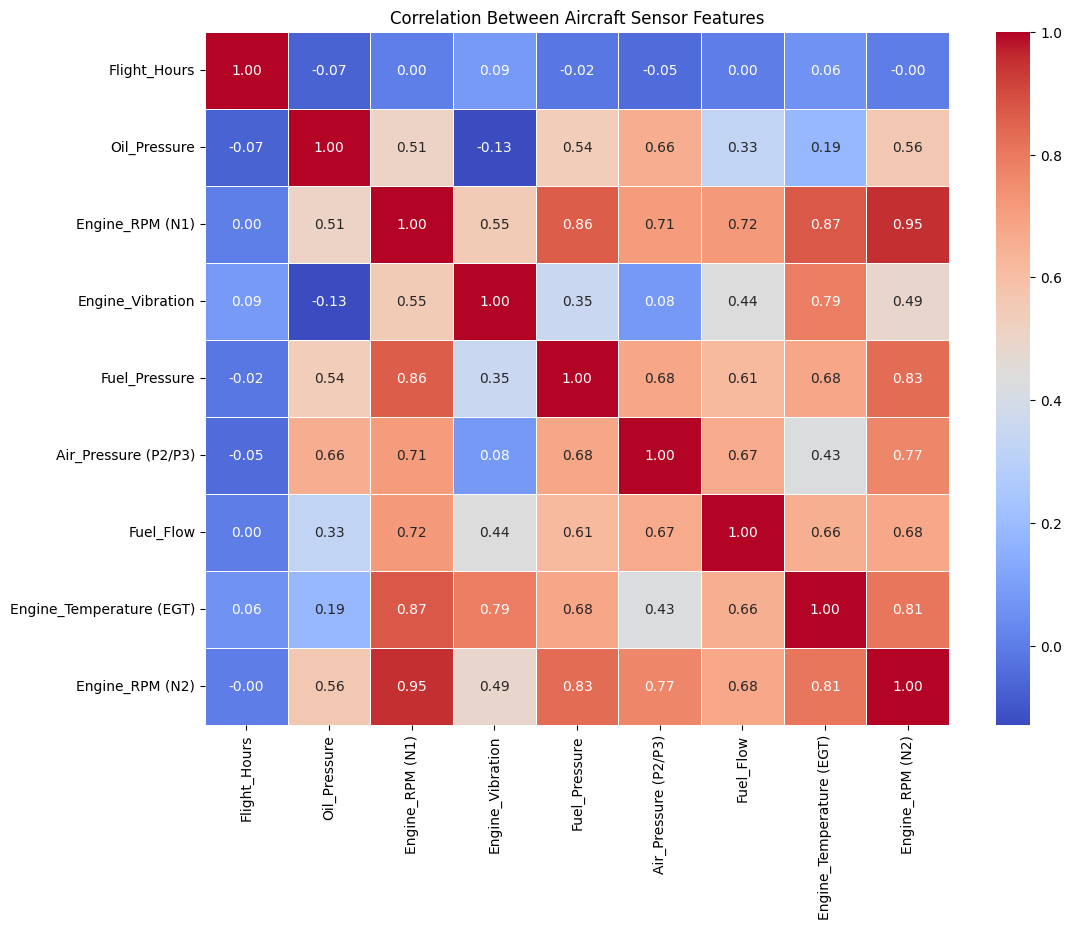

In [560]:
plt.figure(figsize=(12, 9))

numerical_columns = [
    "Flight_Hours",
    "Oil_Pressure",
    "Engine_RPM (N1)",
    "Engine_Vibration",
    "Fuel_Pressure",
    "Air_Pressure (P2/P3)",
    "Fuel_Flow",
    "Engine_Temperature (EGT)",
    "Engine_RPM (N2)"
]

correlation = df[numerical_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Aircraft Sensor Features")
plt.show()

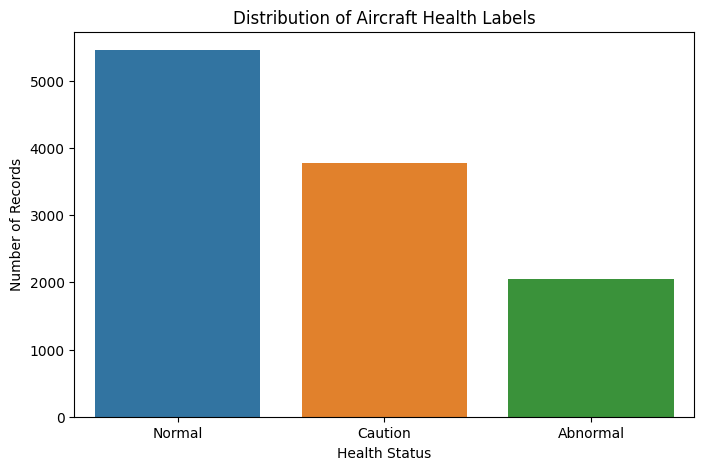

In [561]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Health_Label", hue="Health_Label")

plt.title("Distribution of Aircraft Health Labels")
plt.xlabel("Health Status")
plt.ylabel("Number of Records")
plt.show()

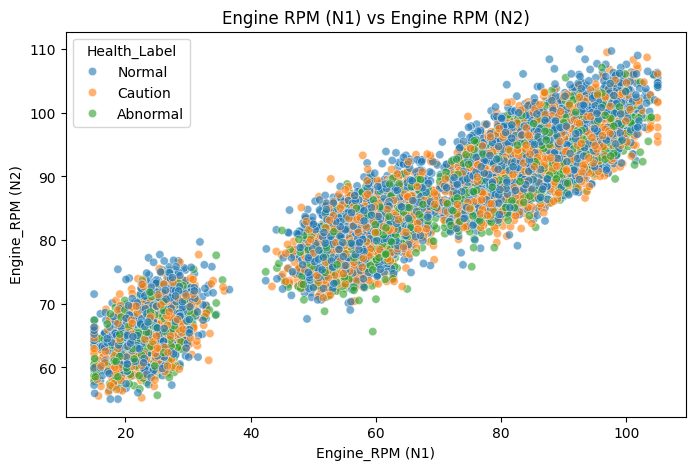

In [562]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Engine_RPM (N1)", y="Engine_RPM (N2)", hue="Health_Label", alpha=0.6)
plt.title("Engine RPM (N1) vs Engine RPM (N2)")
plt.show()

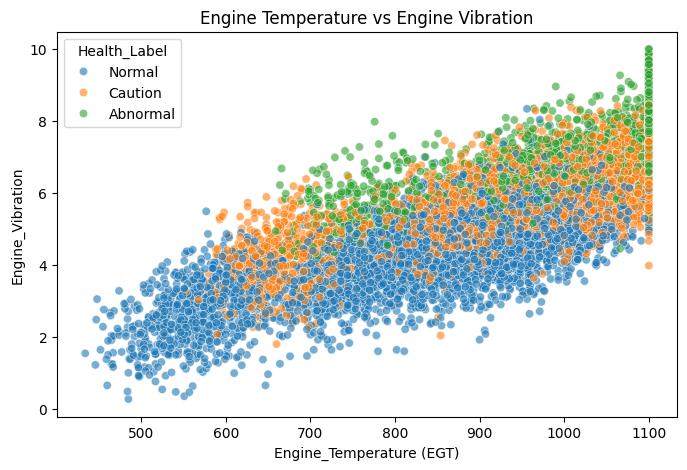

In [563]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Engine_Temperature (EGT)", y="Engine_Vibration", hue="Health_Label", alpha=0.6)
plt.title("Engine Temperature vs Engine Vibration")
plt.show()

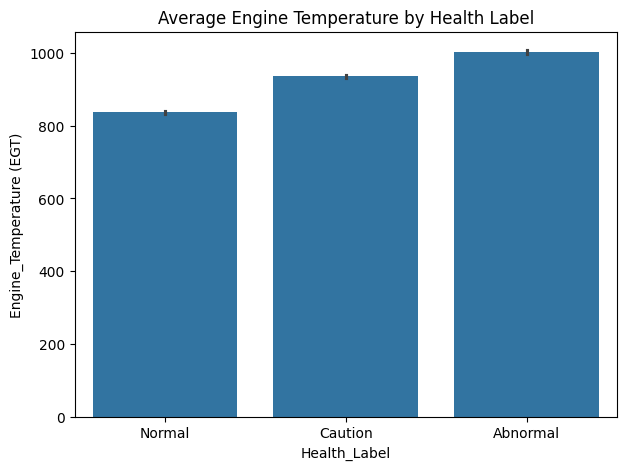

In [564]:
plt.figure(figsize=(7, 5))
sns.barplot(data=df, x="Health_Label", y="Engine_Temperature (EGT)")
plt.title("Average Engine Temperature by Health Label")
plt.show()

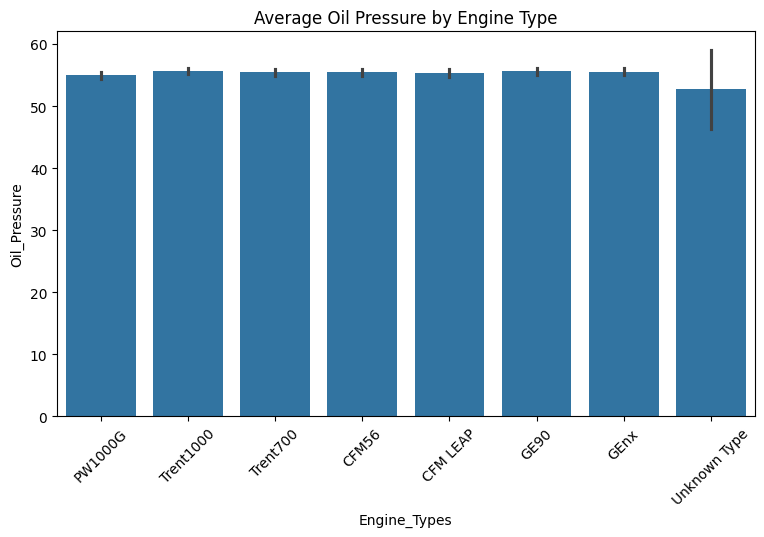

In [565]:
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="Engine_Types", y="Oil_Pressure")
plt.title("Average Oil Pressure by Engine Type")
plt.xticks(rotation=45)
plt.show()

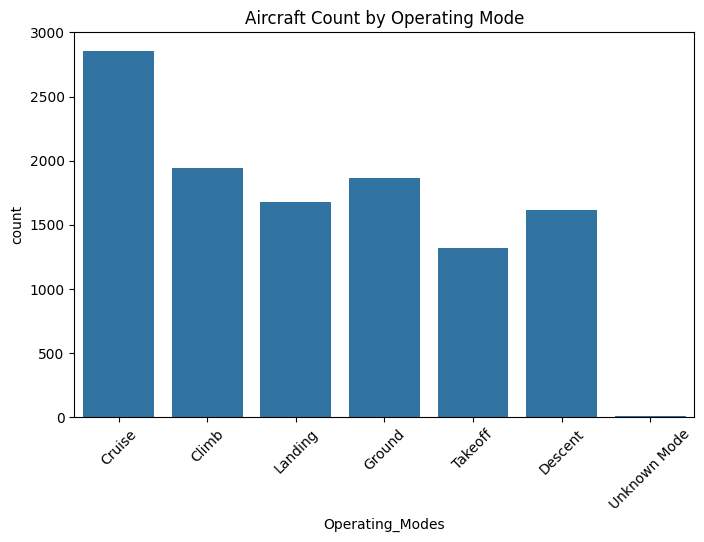

In [566]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Operating_Modes")
plt.title("Aircraft Count by Operating Mode")
plt.xticks(rotation=45)
plt.show()

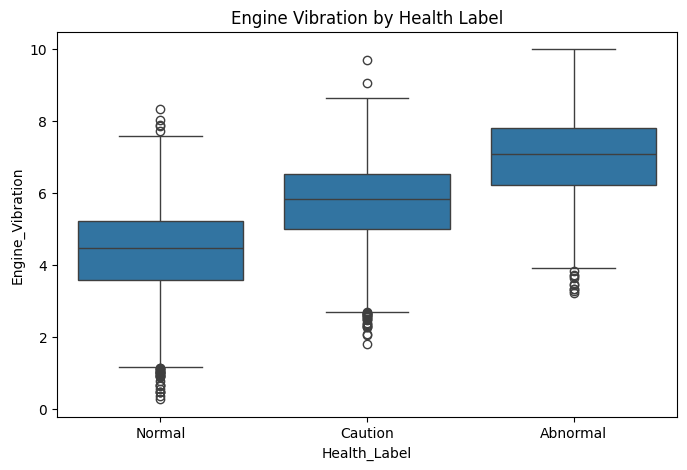

In [567]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Health_Label", y="Engine_Vibration")
plt.title("Engine Vibration by Health Label")
plt.show()

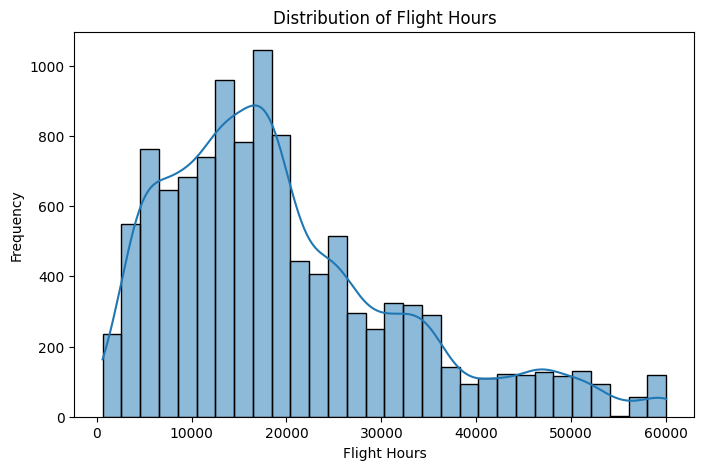

In [568]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Flight_Hours", bins=30, kde=True)
plt.title("Distribution of Flight Hours")
plt.xlabel("Flight Hours")
plt.ylabel("Frequency")
plt.show()

In [569]:
X = df.drop("Health_Label", axis=1)

y = df["Health_Label"]

In [570]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (11283, 11)
Target shape: (11283,)


In [571]:
numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns

categorical_columns = X.select_dtypes(include=["object"]).columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

Numerical Columns:
['Flight_Hours', 'Oil_Pressure', 'Engine_RPM (N1)', 'Engine_Vibration', 'Fuel_Pressure', 'Air_Pressure (P2/P3)', 'Fuel_Flow', 'Engine_Temperature (EGT)', 'Engine_RPM (N2)']

Categorical Columns:
['Operating_Modes', 'Engine_Types']


In [572]:
X = pd.get_dummies(
    X,
    columns=["Operating_Modes", "Engine_Types"],
    dtype=int
)

In [573]:
print("New Features Shape:", X.shape)
print(X.head())

New Features Shape: (11283, 24)
   Flight_Hours  Oil_Pressure  Engine_RPM (N1)  Engine_Vibration  \
0       16761.7          66.2             83.8              5.06   
1        4186.1          71.8             83.3              4.29   
2        3275.3          57.8             79.5              6.44   
3       26424.4          69.8             64.8              2.48   
4       12550.5          27.7             16.4              4.72   

   Fuel_Pressure  Air_Pressure (P2/P3)  Fuel_Flow  Engine_Temperature (EGT)  \
0           48.1                 225.1     4117.0                    1009.0   
1           48.3                 266.6     7626.0                     917.0   
2           43.0                 221.5     7535.0                    1058.0   
3           47.3                 233.7     6414.0                     789.0   
4           23.5                 152.7      882.0                     716.0   

   Engine_RPM (N2)  Operating_Modes_Climb  ...  Operating_Modes_Takeoff  \
0        

In [574]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [575]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (9026, 24)
Testing Features: (2257, 24)
Training Target: (9026,)
Testing Target: (2257,)


In [576]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=10,
    random_state=42
)

In [577]:
model.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current n

In [578]:
y_pred = model.predict(X_test)

In [579]:
results = pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": y_pred[:10]
})

results

,Actual,Predicted
0,Caution,Caution
1,Normal,Normal
2,Caution,Caution
3,Abnormal,Abnormal
4,Normal,Normal
5,Abnormal,Abnormal
6,Caution,Caution
7,Normal,Normal
8,Normal,Normal
9,Normal,Normal


In [580]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Accuracy: 0.7864421798848028
Accuracy Percentage: 78.64421798848028 %


In [581]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nOutcome Values:")
print(cm.ravel())

print("\nAccuracy:")
print(accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[315  94   0]
 [ 90 527 139]
 [  1 158 933]]

Outcome Values:
[315  94   0  90 527 139   1 158 933]

Accuracy:
0.7864421798848028

Classification Report:
              precision    recall  f1-score   support

    Abnormal       0.78      0.77      0.77       409
     Caution       0.68      0.70      0.69       756
      Normal       0.87      0.85      0.86      1092

    accuracy                           0.79      2257
   macro avg       0.77      0.77      0.77      2257
weighted avg       0.79      0.79      0.79      2257



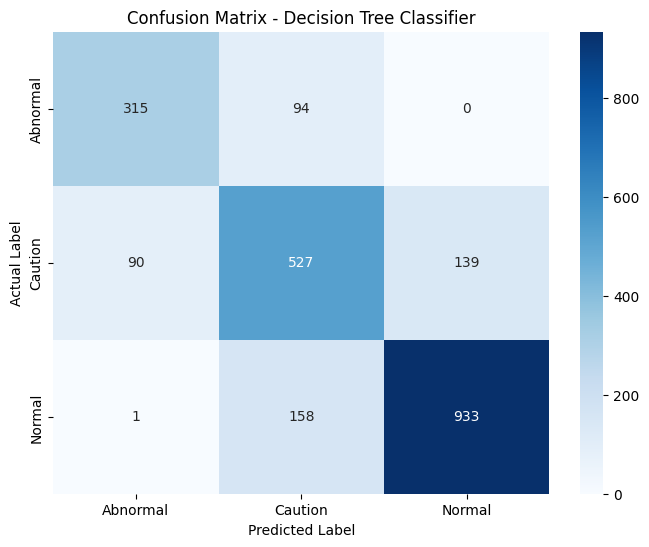

In [582]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Abnormal", "Caution", "Normal"],
    yticklabels=["Abnormal", "Caution", "Normal"]
)

plt.title("Confusion Matrix - Decision Tree Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()